# Exercise 14: PCA-based Classification
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

Based on **Practice 20**, do the following on the **Wine dataset** (`load_wine`),
which is a 3-class classification problem (`class_0`, `class_1`, `class_2`) with **13 features**.

Use **Logistic Regression** as the downstream classifier.

1) Load the Wine dataset. Use **all 13 features** and **all 3 classes**.

2) Split the data with `test_size=0.3`, `random_state=2026`, `stratify=y`.

3) Standardize the training set and fit PCA with all 13 components.
   Plot the **scree plot** and the **cumulative explained variance**.
   Report the number of components needed to reach **90 %** and **95 %** of total variance.

4) Visualize the **2D PCA projection** of the training set (colored by class).

5) Build a `Pipeline`: **StandardScaler -> PCA -> LogisticRegression**
   (use `LogisticRegression(max_iter=1000, random_state=2026)`).
   Fit the pipeline with `M = 2` and report the train and test accuracy.

6) Report the **confusion matrix** (visual) and the **classification report**
   for the best PCA pipeline on the test set.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
feature_names = wine.feature_names
class_names = wine.target_names

print("Feature names:", feature_names)
print("Class names  :", class_names)
print("Shape of X   :", X.shape)
print("Shape of y   :", y.shape)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=2026,
    stratify=y
)

print('X_train:', X_train.shape, ' X_test:', X_test.shape)

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class names  : ['class_0' 'class_1' 'class_2']
Shape of X   : (178, 13)
Shape of y   : (178,)
X_train: (124, 13)  X_test: (54, 13)


 PC index    EVR  Cum. EVR
        1 0.3744    0.3744
        2 0.1954    0.5698
        3 0.0981    0.6679
        4 0.0712    0.7391
        5 0.0659    0.8050
        6 0.0470    0.8520
        7 0.0414    0.8934
        8 0.0266    0.9200
        9 0.0229    0.9429
       10 0.0205    0.9633
       11 0.0160    0.9793
       12 0.0145    0.9938
       13 0.0062    1.0000


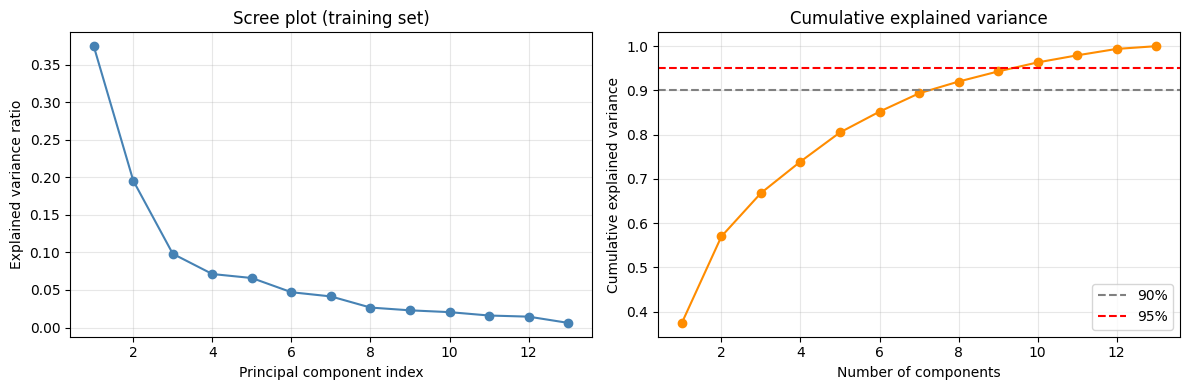

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)

pca_full = PCA()
pca_full.fit(X_train_std)

evr     = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

summary = pd.DataFrame({
    'PC index'  : np.arange(1, len(evr) + 1),
    'EVR'       : evr.round(4),
    'Cum. EVR'  : cum_evr.round(4),
})
print(summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(summary['PC index'], summary['EVR'], 'o-', color='steelblue')
axes[0].set_xlabel('Principal component index')
axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('Scree plot (training set)')
axes[0].grid(alpha=0.3)

axes[1].plot(summary['PC index'], summary['Cum. EVR'], 'o-', color='darkorange')
axes[1].axhline(0.90, color='gray', linestyle='--', label='90%')
axes[1].axhline(0.95, color='red',  linestyle='--', label='95%')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_title('Cumulative explained variance')
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

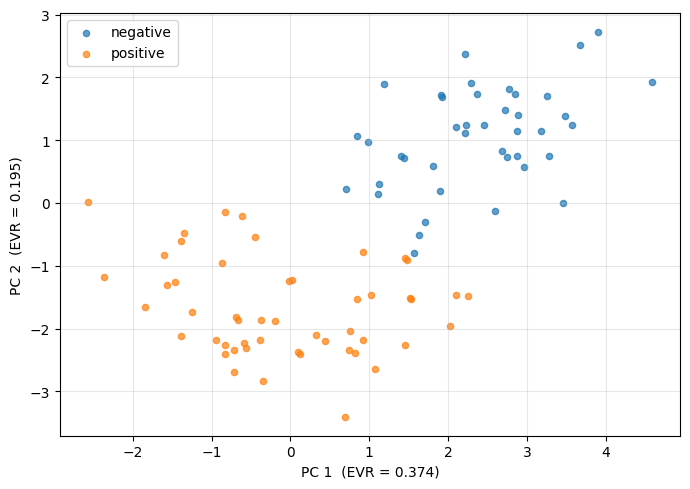

In [ ]:
pca2 = PCA(n_components=2)
X_train_2d = pca2.fit_transform(X_train_std)

plt.figure(figsize=(7, 5))
for cls, name, color in zip([0, 1], ['negative', 'positive'], ['tab:blue', 'tab:orange']):
    pts = X_train_2d[y_train == cls]
    plt.scatter(pts[:, 0], pts[:, 1], label=name, alpha=0.7, s=20, c=color)
plt.xlabel(f'PC 1  (EVR = {pca2.explained_variance_ratio_[0]:.3f})')
plt.ylabel(f'PC 2  (EVR = {pca2.explained_variance_ratio_[1]:.3f})')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca',    PCA(n_components=2)),
    ('clf',    LogisticRegression(
                    max_iter=1000,
                    random_state=2026,
                    n_jobs=-1)),
])

pipe.fit(X_train, y_train)
print('Pipeline (M = 2) training accuracy:', round(pipe.score(X_train, y_train), 2))
print('Pipeline (M = 2) test     accuracy:', round(pipe.score(X_test,  y_test ), 2))

Pipeline (M = 2) training accuracy: 0.98
Pipeline (M = 2) test     accuracy: 0.94


ValueError: The number of FixedLocator locations (3), usually from a call to set_ticks, does not match the number of labels (2).

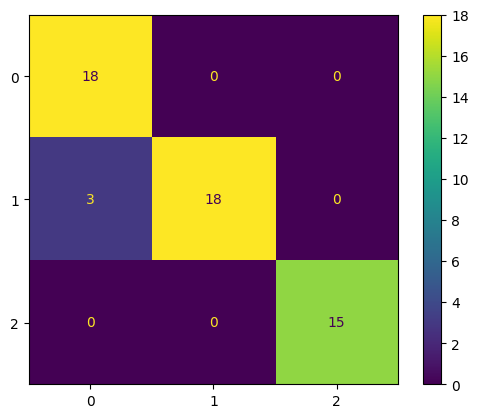

In [28]:
from sklearn.model_selection import GridSearchCV

param_grid = {'pca__n_components': list(range(1, X_train.shape[1] + 1))}

grid = GridSearchCV(
    pipe, param_grid,
    cv=5, scoring='accuracy', n_jobs=-1, return_train_score=True,
    refit=True
)
grid.fit(X_train, y_train)

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

y_pred = grid.best_estimator_.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot()
plt.title(f'Confusion matrix - PCA (M={grid.best_params_["pca__n_components"]}) -> RF')
plt.show()

print(classification_report(y_test, y_pred, target_names=['negative', 'positive']))